# Credit Risk Modeling - Phase 1: Sound Evaluation

Built on top of the tutorial by Onur Baltaci ("Credit Risk Modeling Using Machine Learning"),
with the following extensions:

1. Keep all 1,000 rows: missing `Saving accounts` / `Checking account` are treated as an informative category (`none`) instead of being dropped.
2. Remove `Sex` from the model features (fair lending); add `Purpose`.
3. Model selection with stratified 5-fold cross-validation on the training set only; the test set is used once.
4. Credit-risk metrics: ROC-AUC, Gini, KS, compared against a majority-class baseline.
5. Cost-sensitive decision threshold using the German Credit cost matrix (bad-as-good = 5, good-as-bad = 1), tuned on out-of-fold predictions.
6. A single sklearn `Pipeline` (preprocessing + model) and the chosen threshold are saved together for the Streamlit app.

Positive class convention: `1 = bad` (default). The model output is a probability of default (PD).

## 1. Setup

In [ ]:
# Uncomment on Colab if xgboost is missing
# !pip install -q xgboost kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, accuracy_score)
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 2. Load data

In [ ]:
# Set LOCAL_CSV to a file path to skip the Kaggle download (e.g. for offline runs)
LOCAL_CSV = os.environ.get("CREDIT_CSV")

if LOCAL_CSV:
    csv_path = LOCAL_CSV
else:
    import kagglehub
    path = kagglehub.dataset_download("kabure/german-credit-data-with-risk")
    csv_path = os.path.join(path, "german_credit_data.csv")

df = pd.read_csv(csv_path)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
print(df.shape)
df.head()

Using Colab cache for faster access to the 'german-credit-data-with-risk' dataset.
(1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## 3. Missing values: drop or keep?

The original tutorial ran `dropna()`, which removed 478 of 1,000 rows (about 48%).
In this dataset a missing account status most likely means the applicant has no such account,
which is itself a risk signal. Below we check whether the bad rate differs for missing rows.
If it does, dropping them throws away signal and biases the sample.

In [ ]:
print(df.isna().sum())

for col in ["Saving accounts", "Checking account"]:
    rate = (df.assign(is_missing=df[col].isna())
              .groupby("is_missing")["Risk"]
              .apply(lambda s: (s == "bad").mean())
              .rename("bad_rate"))
    print(f"\n{col}: bad rate by missingness")
    print(rate.round(3))

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

Saving accounts: bad rate by missingness
is_missing
False    0.328
True     0.175
Name: bad_rate, dtype: float64

Checking account: bad rate by missingness
is_missing
False    0.419
True     0.117
Name: bad_rate, dtype: float64


In [ ]:
df[["Saving accounts", "Checking account"]] = df[["Saving accounts", "Checking account"]].fillna("none")

# Target: 1 = bad (default), 0 = good
df["target"] = (df["Risk"] == "bad").astype(int)
print(df["target"].value_counts())
print("Overall bad rate:", round(df["target"].mean(), 3))

target
0    700
1    300
Name: count, dtype: int64
Overall bad rate: 0.3


## 4. Features

`Sex` is excluded from the model. Using a protected attribute directly in a credit decision is not
acceptable in most lending regulations, and it is kept aside only for a later fairness check (Phase 3).
`Purpose` was unused in the tutorial and is added here.

In [ ]:
num_features = ["Age", "Credit amount", "Duration"]
cat_features = ["Job", "Housing", "Saving accounts", "Checking account", "Purpose"]
features = num_features + cat_features

X = df[features].copy()
X["Job"] = X["Job"].astype(str)  # Job is a skill-level code, treat as categorical
y = df["target"]
sex = df["Sex"]  # kept for Phase 3 fairness audit, not a model input

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print("Train bad rate:", round(y_train.mean(), 3), "| Test bad rate:", round(y_test.mean(), 3))

(800, 8) (200, 8)
Train bad rate: 0.3 | Test bad rate: 0.3


## 5. Preprocessing pipeline

One-hot encoding inside a `ColumnTransformer` replaces the per-column `LabelEncoder` files.
Everything is fitted only on training folds, so there is no leakage, and the app loads one object.
`handle_unknown="ignore"` keeps the app from crashing on unseen categories.

In [ ]:
def make_preprocessor(scale_numeric):
    num_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("num", num_step, num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

neg, pos = np.bincount(y_train)

candidates = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000),
        True,
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        False,
        {"model__n_estimators": [300], "model__max_depth": [4, 6, 10, None],
         "model__min_samples_leaf": [1, 5, 10], "model__class_weight": [None, "balanced"]},
    ),
    "ExtraTrees": (
        ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        False,
        {"model__n_estimators": [300], "model__max_depth": [4, 6, 10, None],
         "model__min_samples_leaf": [1, 5, 10], "model__class_weight": [None, "balanced"]},
    ),
    "XGBoost": (
        XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),
        False,
        {"model__n_estimators": [200], "model__max_depth": [2, 3, 4],
         "model__learning_rate": [0.03, 0.1], "model__subsample": [0.8],
         "model__colsample_bytree": [0.8], "model__scale_pos_weight": [1, neg / pos]},
    ),
}

## 6. Model selection with stratified 5-fold CV (train set only)

Scoring is ROC-AUC, which measures ranking quality across all thresholds and is not fooled by class imbalance.
We report the mean and standard deviation across folds. If two models differ by less than about one
standard deviation, treat them as a tie and prefer the simpler, more explainable one.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, best_pipes = [], {}

for name, (est, scale, grid) in candidates.items():
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", est)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    i = gs.best_index_
    results.append({
        "model": name,
        "cv_auc_mean": gs.cv_results_["mean_test_score"][i],
        "cv_auc_std": gs.cv_results_["std_test_score"][i],
        "best_params": gs.best_params_,
    })
    best_pipes[name] = gs.best_estimator_

cv_table = pd.DataFrame(results).sort_values("cv_auc_mean", ascending=False).reset_index(drop=True)
cv_table["cv_gini_mean"] = 2 * cv_table["cv_auc_mean"] - 1
pd.set_option("display.max_colwidth", 200)
cv_table

,model,cv_auc_mean,cv_auc_std,best_params,cv_gini_mean
0,XGBoost,0.768973,0.052363,"{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__scale_pos_weight': 1, 'model__subsample': 0.8}",0.537946
1,RandomForest,0.762649,0.053871,"{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}",0.525298
2,LogisticRegression,0.750112,0.055464,"{'model__C': 0.1, 'model__class_weight': None}",0.500223
3,ExtraTrees,0.746336,0.060355,"{'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}",0.492671


In [ ]:
# Pick the top CV model by default; override manually if the gap to a simpler model is within one std
best_name = cv_table.loc[0, "model"]
# best_name = "LogisticRegression"
best_pipe = best_pipes[best_name]
print("Selected:", best_name)

Selected: XGBoost


## 7. Cost-sensitive threshold (tuned on out-of-fold predictions)

The German Credit documentation defines a cost matrix: approving a bad applicant costs 5,
rejecting a good applicant costs 1. A 0.5 cut-off implicitly assumes equal costs.

Decision rule: reject if PD >= threshold.
- FN = bad applicant approved (cost 5)
- FP = good applicant rejected (cost 1)

The threshold is chosen on out-of-fold training predictions, so the test set stays untouched.
For a perfectly calibrated model the theoretical optimum is 1 / (1 + 5) = 0.167; the empirical
optimum differs because tree-model probabilities are not calibrated (addressed in Phase 2).

OOF AUC: 0.769
Best threshold (OOF): 0.15 | cost/applicant: 0.555
Cost/applicant at 0.50: 0.921


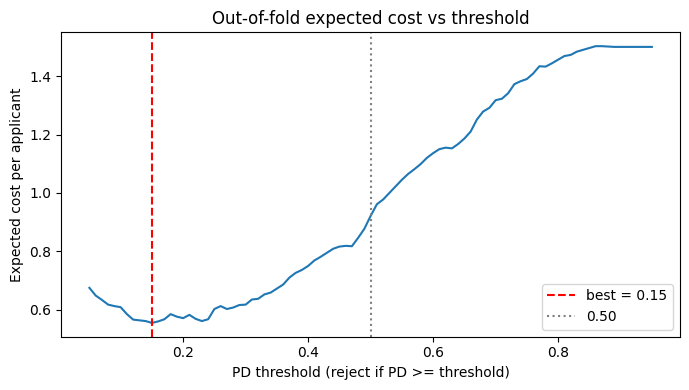

In [ ]:
COST_FN, COST_FP = 5, 1

def expected_cost(y_true, pd_hat, thr):
    pred_bad = (pd_hat >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred_bad, labels=[0, 1]).ravel()
    return (COST_FN * fn + COST_FP * fp) / len(y_true)

oof_pd = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
oof_costs = np.array([expected_cost(y_train, oof_pd, t) for t in thresholds])
best_thr = float(thresholds[oof_costs.argmin()])

print(f"OOF AUC: {roc_auc_score(y_train, oof_pd):.3f}")
print(f"Best threshold (OOF): {best_thr:.2f} | cost/applicant: {oof_costs.min():.3f}")
print(f"Cost/applicant at 0.50: {expected_cost(y_train, oof_pd, 0.5):.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, oof_costs)
plt.axvline(best_thr, ls="--", c="red", label=f"best = {best_thr:.2f}")
plt.axvline(0.5, ls=":", c="gray", label="0.50")
plt.xlabel("PD threshold (reject if PD >= threshold)")
plt.ylabel("Expected cost per applicant")
plt.title("Out-of-fold expected cost vs threshold")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Final evaluation on the held-out test set (run once)

Metrics:
- **ROC-AUC**: probability that a random bad applicant gets a higher PD than a random good one.
- **Gini** = 2 * AUC - 1, the convention used by banks.
- **KS**: maximum gap between the cumulative score distributions of bad and good applicants.
- **Baseline**: a model that always predicts the majority class ("good") gets about 70% accuracy and AUC 0.5.
  Any accuracy number must be read against this.

With about 200 test rows, metrics carry noticeable sampling noise, so a bootstrap confidence interval for AUC is shown.

In [ ]:
best_pipe.fit(X_train, y_train)
test_pd = best_pipe.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, test_pd)
fpr, tpr, roc_thr = roc_curve(y_test, test_pd)
ks = np.max(tpr - fpr)

# Bootstrap 95% CI for test AUC
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    boot.append(roc_auc_score(y_arr[idx], test_pd[idx]))
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_acc = accuracy_score(y_test, baseline.predict(X_test))

summary = pd.DataFrame({
    "metric": ["ROC-AUC", "AUC 95% CI (bootstrap)", "Gini", "KS",
               "Baseline accuracy (always good)",
               "Accuracy @ 0.50", f"Accuracy @ {best_thr:.2f}",
               "Cost/applicant @ 0.50", f"Cost/applicant @ {best_thr:.2f}",
               "Cost/applicant approve-all"],
    "value": [round(auc, 3), f"{ci_lo:.3f} - {ci_hi:.3f}", round(2 * auc - 1, 3), round(ks, 3),
              round(base_acc, 3),
              round(accuracy_score(y_test, (test_pd >= 0.5).astype(int)), 3),
              round(accuracy_score(y_test, (test_pd >= best_thr).astype(int)), 3),
              round(expected_cost(y_test, test_pd, 0.5), 3),
              round(expected_cost(y_test, test_pd, best_thr), 3),
              round(expected_cost(y_test, test_pd, 1.01), 3)],
})
print("Model:", best_name)
summary

Model: XGBoost


,metric,value
0,ROC-AUC,0.785
1,AUC 95% CI (bootstrap),0.713 - 0.855
2,Gini,0.57
3,KS,0.45
4,Baseline accuracy (always good),0.7
5,Accuracy @ 0.50,0.755
6,Accuracy @ 0.15,0.59
7,Cost/applicant @ 0.50,0.885
8,Cost/applicant @ 0.15,0.55
9,Cost/applicant approve-all,1.5


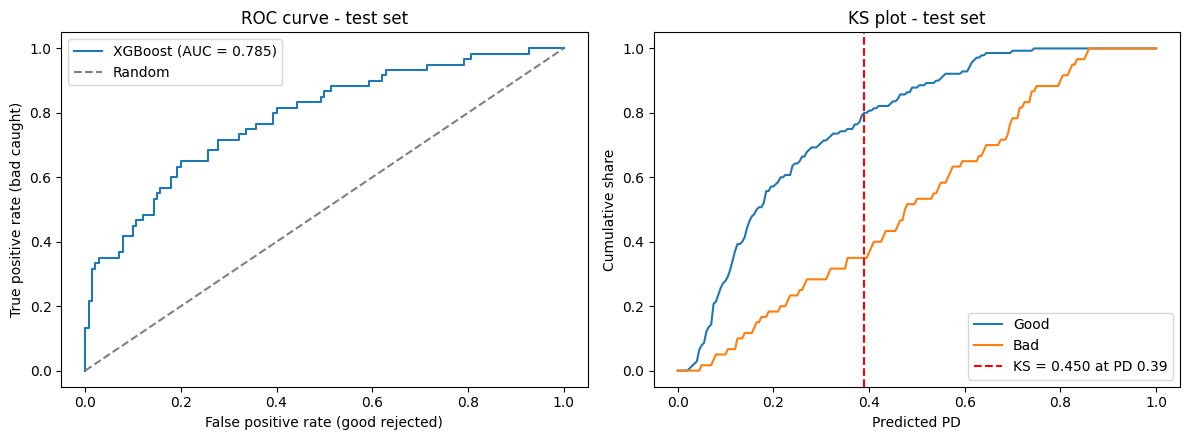

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ROC curve
axes[0].plot(fpr, tpr, label=f"{best_name} (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", c="gray", label="Random")
axes[0].set_xlabel("False positive rate (good rejected)")
axes[0].set_ylabel("True positive rate (bad caught)")
axes[0].set_title("ROC curve - test set"); axes[0].legend()

# KS plot: cumulative distribution of PD for bad vs good
grid = np.linspace(0, 1, 201)
cdf_bad = [(test_pd[y_arr == 1] <= g).mean() for g in grid]
cdf_good = [(test_pd[y_arr == 0] <= g).mean() for g in grid]
gap = np.abs(np.array(cdf_good) - np.array(cdf_bad))
g_star = grid[gap.argmax()]
axes[1].plot(grid, cdf_good, label="Good")
axes[1].plot(grid, cdf_bad, label="Bad")
axes[1].axvline(g_star, ls="--", c="red", label=f"KS = {gap.max():.3f} at PD {g_star:.2f}")
axes[1].set_xlabel("Predicted PD"); axes[1].set_ylabel("Cumulative share")
axes[1].set_title("KS plot - test set"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
for thr in [0.5, best_thr]:
    pred_bad = (test_pd >= thr).astype(int)
    cm = confusion_matrix(y_test, pred_bad, labels=[0, 1])
    print(f"\n=== Threshold {thr:.2f} ===")
    print(pd.DataFrame(cm, index=["actual good", "actual bad"],
                       columns=["pred good (approve)", "pred bad (reject)"]))
    print(classification_report(y_test, pred_bad, target_names=["good", "bad"], digits=3))


=== Threshold 0.50 ===
             pred good (approve)  pred bad (reject)
actual good                  123                 17
actual bad                    32                 28
              precision    recall  f1-score   support

        good      0.794     0.879     0.834       140
         bad      0.622     0.467     0.533        60

    accuracy                          0.755       200
   macro avg      0.708     0.673     0.684       200
weighted avg      0.742     0.755     0.744       200


=== Threshold 0.15 ===
             pred good (approve)  pred bad (reject)
actual good                   65                 75
actual bad                     7                 53
              precision    recall  f1-score   support

        good      0.903     0.464     0.613       140
         bad      0.414     0.883     0.564        60

    accuracy                          0.590       200
   macro avg      0.658     0.674     0.589       200
weighted avg      0.756     0.590     0.5

## 9. Save artifacts for the app

One file holds the full pipeline, the threshold, and metadata, so the app cannot drift out of sync
with the encoders.

In [ ]:
artifact = {
    "pipeline": best_pipe,
    "threshold": best_thr,
    "model_name": best_name,
    "features": features,
    "num_features": num_features,
    "cat_features": cat_features,
    "positive_class": "bad",
    "cost_matrix": {"bad_as_good": COST_FN, "good_as_bad": COST_FP},
}

# XGBoost: store the booster in its native portable format instead of pickling it
if best_name == "XGBoost":
    best_pipe.named_steps["model"].save_model("xgb_model.ubj")
    artifact["pipeline"] = Pipeline([("prep", best_pipe.named_steps["prep"])])
    artifact["xgb_path"] = "xgb_model.ubj"

joblib.dump(artifact, "credit_risk_model.pkl")
print("Saved:", "credit_risk_model.pkl", artifact.get("xgb_path", ""))

Saved: credit_risk_model.pkl xgb_model.ubj
